
# Desafio 1 — Análise de Crédito | CredAIR

## 1. Entendimento do problema

O objetivo deste projeto é investigar os fatores associados à inadimplência em propostas de crédito e desenvolver um modelo de classificação utilizando Regressão Logística.

A variável resposta é `inadimplente`, que indica se uma proposta resultou ou não em inadimplência.

O problema será tratado como aprendizado supervisionado de classificação binária, pois os dados históricos possuem a resposta conhecida para cada registro.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#%pip install seaborn
import seaborn as sns

In [3]:
df = pd.read_csv("dataset.csv")
df

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,31,PB,Ensino Médio,3374.04,8,677,10198.45,24,Outros,2,0
4996,64,AM,Ensino Superior,3638.91,20,643,15374.40,24,Reforma,1,0
4997,48,MT,Ensino Médio,2211.31,21,486,8236.10,48,Saúde,0,1
4998,19,AP,Ensino Superior,14709.61,4,766,10617.90,18,Veículo,1,0


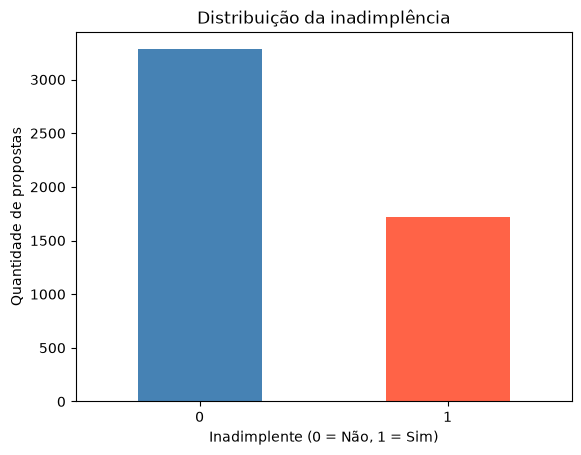

In [4]:
df["inadimplente"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "tomato"]
)

plt.title("Distribuição da inadimplência")
plt.xlabel("Inadimplente (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade de propostas")
plt.xticks(rotation=0)
plt.show()

In [7]:
faixas_score = pd.cut(
    df["score_credito"],
    bins=[0, 500, 600, 700, 800, 1000],
    right=False
)

taxa_score = (
    df.groupby(faixas_score, observed=False)["inadimplente"]
      .agg(["count", "mean"])
)

taxa_score["mean"] = taxa_score["mean"] * 100

display(taxa_score.rename(columns={
    "count": "quantidade",
    "mean": "taxa_inadimplencia_%"
}))

,quantidade,taxa_inadimplencia_%
score_credito,,
"[0, 500)",188,63.829787
"[500, 600)",1163,51.590714
"[600, 700)",2174,34.222631
"[700, 800)",1255,18.486056
"[800, 1000)",220,10.909091


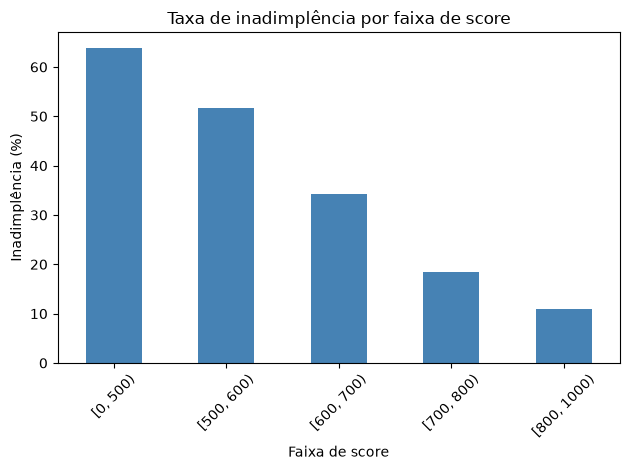

In [8]:
taxa_score["mean"].plot(kind="bar", color="steelblue")

plt.title("Taxa de inadimplência por faixa de score")
plt.xlabel("Faixa de score")
plt.ylabel("Inadimplência (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()